# Lapis 2 — Pembaca Alasan (MAP)
B0 TF-IDF+LR (lokal) vs M1 mDeBERTa-v3-base (kernel privat Kaggle `remediaide-l2-mdeberta`). Semua angka CV (MAP tanpa fold test terkunci, D-06).

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from remediaide_ml.paths import TABLES, FIGURES, PROCESSED
pd.set_option("display.precision", 4)
def js(name): return json.loads((TABLES / name).read_text())

## CV: MAP@3 (split acak) dan macro-F1 category3 (per soal)

In [2]:
pd.read_csv(TABLES / 'L2_cv.csv')

,model,split,metric,value,ci_lo,ci_hi,fold_std,n,ci_unit
0,M1 mDeBERTa-v3-base,random (5-fold),MAP@3,0.9123,0.9101,0.9145,0.0020,36696,NaN
1,B0 TF-IDF+LR,random (5-fold),MAP@3,0.9159,0.9140,0.9179,0.0021,36696,NaN
2,selisih mDeBERTa − TF-IDF,random (5-fold),MAP@3,-0.0036,-0.0055,-0.0017,NaN,36696,NaN
3,M1 mDeBERTa-v3-base,"per soal (5-fold, 3 soal/fold)",macro-F1 category3,0.6375,0.5839,0.6849,0.0668,36696,soal (15 klaster)
4,B0 TF-IDF+LR,"per soal (5-fold, 3 soal/fold)",macro-F1 category3,0.6112,0.5422,0.6740,0.0786,36696,soal (15 klaster)
5,selisih mDeBERTa − TF-IDF,"per soal (5-fold, 3 soal/fold)",macro-F1 category3,0.0263,-0.0347,0.0781,NaN,36696,soal (15 klaster)


## E3 — jebakan jawaban benar

In [3]:
pd.read_csv(TABLES / 'E3_true_misconception.csv')

,model,recall,precision,f1,pr_auc,n_pos,note,recall_lo,recall_hi,precision_lo,precision_hi,source
0,B0 aturan CRI v1,0.0000,NaN,0.0000,NaN,403,benar + yakin selalu 'Paham' (desain),NaN,NaN,NaN,NaN,NaN
1,B0 TF-IDF,0.3747,0.8207,0.5145,0.5819,403,NaN,0.3294,0.4216,0.7602,0.8736,runs/20261118-2131_l2_tfidf/oof_target.parquet
2,M1 mDeBERTa,0.3226,0.8075,0.4610,0.5490,403,NaN,0.2766,0.3673,0.7450,0.8679,runs/20261118-2202_l2_mdeberta_kaggle/kaggle_o...


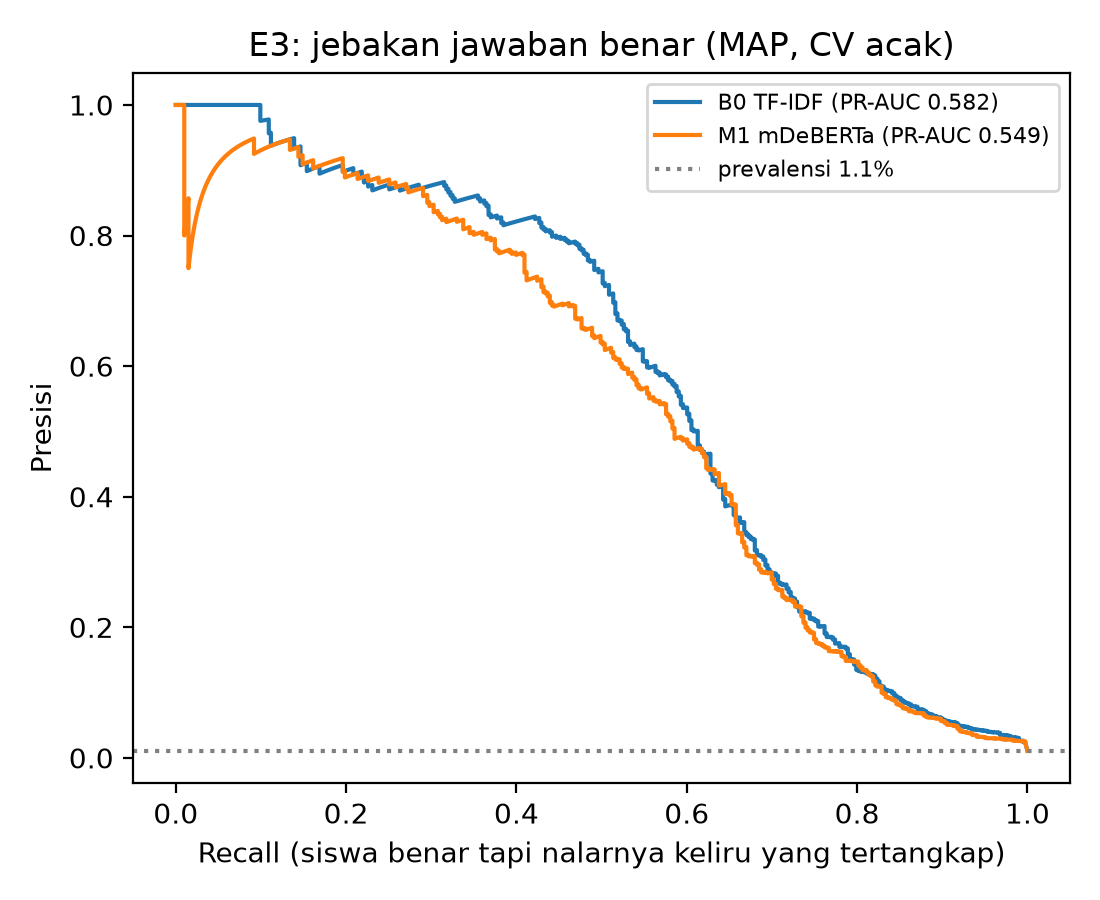

In [4]:
display(Image(FIGURES / 'E3_pr_curve.png', width=520))

In [5]:
pd.read_csv(TABLES / 'E3_queue_cv.csv')

,model,ambang,n_positif,positif_masuk_antrean,recall_antrean,presisi_antrean,porsi_jawaban_benar_ditandai,split
0,tfidf,0.20,322,161,0.5000,0.6940,0.0141,"CV MAP, 80% baris evaluasi (bukan kalibrasi)"
1,mdeberta,0.25,322,165,0.5124,0.5749,0.0174,"CV MAP, 80% baris evaluasi (bukan kalibrasi)"


## E4 — lintas bahasa (terjemahan mesin, fold 0)

In [6]:
pd.read_csv(TABLES / 'E4_crosslingual.csv').drop(columns=['catatan'], errors='ignore')

,metric,EN,ID,selisih_ID_minus_EN,ci_lo,ci_hi,n,model,selisih
0,MAP@3,0.9159,0.7656,-0.1503,-0.1579,-0.1428,7340,B0 TF-IDF+LR,NaN
1,macro-F1 category3,0.8390,0.6308,-0.2082,-0.2208,-0.1962,7340,B0 TF-IDF+LR,NaN
2,recall True_Misconception,0.3418,0.0127,-0.3291,NaN,NaN,7340,B0 TF-IDF+LR,NaN
3,MAP@3,0.9110,0.8945,-0.0165,-0.0203,-0.0129,7340,M1 mDeBERTa-v3-base,NaN
4,macro-F1 category3,0.8437,0.8118,-0.0319,-0.0397,-0.0244,7340,M1 mDeBERTa-v3-base,NaN
5,recall True_Misconception,0.3038,0.2025,-0.1013,NaN,NaN,7340,M1 mDeBERTa-v3-base,NaN
6,MAP@3 (input ID),NaN,NaN,NaN,0.1211,0.1361,7340,selisih mDeBERTa − TF-IDF,0.1289
7,macro-F1 category3 (input ID),NaN,NaN,NaN,0.1680,0.1939,7340,selisih mDeBERTa − TF-IDF,0.1810


## Kamus miskonsepsi (Rittle-Johnson dkk. 2025, Tabel 1) + terjemahan Indonesia

In [7]:
pd.read_csv(TABLES / 'map_misconception_dictionary.csv').head(12)

,label,question_ids,topik_en,topik_id,deskripsi_en,deskripsi_id,n_baris,sumber
0,WNB,31772,Fraction Representation,Representasi pecahan,Believes numerator and denominator of a fracti...,Menganggap pembilang dan penyebut sebagai dua ...,262,"Rittle-Johnson dkk. 2025, AIME-Con WIP, Tabel ..."
1,Incomplete,31772,Fraction Representation,Representasi pecahan,Incomplete steps: fails to simplify fraction,Langkah belum tuntas: tidak menyederhanakan pe...,1359,"Rittle-Johnson dkk. 2025, AIME-Con WIP, Tabel ..."
2,Adding_across,33472,Adding Fractions,Menjumlah pecahan,Adding numerators and denominators without fin...,Menjumlahkan pembilang dengan pembilang dan pe...,307,"Rittle-Johnson dkk. 2025, AIME-Con WIP, Tabel ..."
3,Denominator-only_change,33472,Adding Fractions,Menjumlah pecahan,Finds common denominator and adds numerators,Menyamakan penyebut tetapi pembilangnya tidak ...,336,"Rittle-Johnson dkk. 2025, AIME-Con WIP, Tabel ..."
4,Incorrect_equivalent_fraction_addition,33472,Adding Fractions,Menjumlah pecahan,"Creates equivalent fractions, and adds numerat...","Membuat pecahan senilai, lalu menjumlahkan pem...",9,"Rittle-Johnson dkk. 2025, AIME-Con WIP, Tabel ..."
5,Irrelevant,31777,Finding Fraction of Set #1,Pecahan dari himpunan #1,Attending to irrelevant feature,Memperhatikan informasi yang tidak relevan,41,"Rittle-Johnson dkk. 2025, AIME-Con WIP, Tabel ..."
6,Incomplete,31777,Finding Fraction of Set #1,Pecahan dari himpunan #1,Incomplete steps: Calculates unit fraction only,Langkah belum tuntas: hanya menghitung pecahan...,76,"Rittle-Johnson dkk. 2025, AIME-Con WIP, Tabel ..."
7,Wrong_Fraction,31777,Finding Fraction of Set #1,Pecahan dari himpunan #1,Calculates fraction for the wrong target,Menghitung pecahan untuk bagian yang salah,273,"Rittle-Johnson dkk. 2025, AIME-Con WIP, Tabel ..."
8,Incomplete,33471,Finding Fraction of Set #2,Pecahan dari himpunan #2,Incomplete steps: Calculates unit fraction only,Langkah belum tuntas: hanya menghitung pecahan...,19,"Rittle-Johnson dkk. 2025, AIME-Con WIP, Tabel ..."
9,Wrong_fraction,33471,Finding Fraction of Set #2,Pecahan dari himpunan #2,Calculates fraction for the wrong target,Menghitung pecahan untuk bagian yang salah,418,"Rittle-Johnson dkk. 2025, AIME-Con WIP, Tabel ..."
